## CSE258 ASSIGNMENT 2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

import ast
import gzip
from pathlib import Path

from itertools import islice

from scipy.stats import spearmanr

## Introduction

General intro info goes here

### Introduction to Columns

`col1`: 

## The Data

In [ ]:
user_items_path = Path("australian_users_items.json") / "australian_users_items.json"
user_item_columns = [
    "user_id",
    "item_id",
    "item_name",
    "playtime_forever",
    "playtime_2weeks",
]
user_item_batches = []

with user_items_path.open(encoding="utf-8") as item_file:
    while profile_lines := list(islice(item_file, 1_000)):
        rows = []
        for line in profile_lines:
            profile = ast.literal_eval(line)
            for item in profile["items"]:
                rows.append(
                    (
                        profile["user_id"],
                        item["item_id"],
                        item["item_name"],
                        item["playtime_forever"],
                        item["playtime_2weeks"],
                    )
                )
        user_item_batches.append(
            pd.DataFrame.from_records(rows, columns=user_item_columns)
        )

user_items = pd.concat(user_item_batches, ignore_index=True)
del user_item_batches
user_items.head()


Loaded 5,153,209 user-game records.


,user_id,item_id,item_name,playtime_forever,playtime_2weeks
0,76561197970982479,10,Counter-Strike,6,0
1,76561197970982479,20,Team Fortress Classic,0,0
2,76561197970982479,30,Day of Defeat,7,0
3,76561197970982479,40,Deathmatch Classic,0,0
4,76561197970982479,50,Half-Life: Opposing Force,0,0


In [123]:
reviews_path = Path("australian_user_reviews.json.gz")
review_rows = []

with gzip.open(reviews_path, "rt", encoding="utf-8") as review_file:
    for line in review_file:
        profile = ast.literal_eval(line)
        for review in profile["reviews"]:
            review_rows.append({"user_id": profile["user_id"], **review})

reviews = pd.DataFrame.from_records(review_rows)
reviews.head()

,user_id,funny,posted,last_edited,item_id,helpful,recommend,review
0,76561197970982479,,"Posted November 5, 2011.",,1250,No ratings yet,True,Simple yet with great replayability. In my opi...
1,76561197970982479,,"Posted July 15, 2011.",,22200,No ratings yet,True,It's unique and worth a playthrough.
2,76561197970982479,,"Posted April 21, 2011.",,43110,No ratings yet,True,Great atmosphere. The gunplay can be a bit chu...
3,js41637,,"Posted June 24, 2014.",,251610,15 of 20 people (75%) found this review helpful,True,I know what you think when you see this title ...
4,js41637,,"Posted September 8, 2013.",,227300,0 of 1 people (0%) found this review helpful,True,For a simple (it's actually not all that simpl...


## EDA

User Item Dimensions: (5153209, 5)
Review Dimensions: (59305, 8)

Number of unique users: 25458
Number of unique games: 3682

Playtime statistics: 
count    5.153209e+06
mean     9.914951e+02
std      5.418204e+03
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+01
75%      3.550000e+02
max      6.427730e+05
Name: playtime_forever, dtype: float64

Recommendation distribution
recommend
True     52473
False     6832
Name: count, dtype: int64


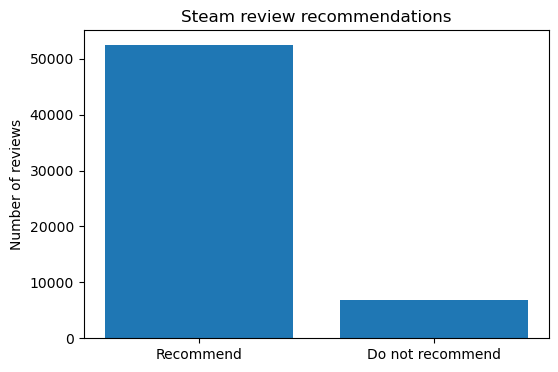

In [124]:
print(f"User Item Dimensions: {user_items.shape}")
print(f"Review Dimensions: {reviews.shape}")

print(f"\nNumber of unique users: {len(reviews['user_id'].unique())}")
print(f"Number of unique games: {len(reviews['item_id'].unique())}")

print("\nPlaytime statistics: ")
print(user_items["playtime_forever"].describe())

print("\nRecommendation distribution")
print(reviews["recommend"].value_counts())

counts = reviews["recommend"].value_counts().reindex([True, False], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Recommend", "Do not recommend"], counts.to_numpy())
ax.set_title("Steam review recommendations")
ax.set_ylabel("Number of reviews")
plt.show()

TODO: why we are merging

In [125]:
keys = ["user_id", "item_id"]

# Keeps only highest playtime review (latest) in the case of duplicate (user, item) review pairs
user_items_deduped = user_items.sort_values(
    "playtime_forever", ascending=False, kind="stable"
).drop_duplicates(subset=keys, keep="first")

merged_deduped = user_items_deduped.merge(
    reviews.drop_duplicates(),
    on=keys,
    how="left",
    validate="one_to_one",
)

Filter to only keep reviews where users actually played the game

In [126]:
# Keep only playtimes greater than 0
non_zero_playtimes = merged_deduped[merged_deduped["playtime_forever"] > 0].reset_index(
    drop="True"
)
non_zero_playtimes

,user_id,item_id,item_name,playtime_forever,playtime_2weeks,funny,posted,last_edited,helpful,recommend,review
0,wolop,4000,Garry's Mod,642773,7299,1 person found this review funny,"Posted July 3, 2011.",,2 of 2 people (100%) found this review helpful,True,Like buiding well you might like this
1,Evilutional,212200,Mabinogi,635295,0,NaN,NaN,NaN,NaN,NaN,NaN
2,76561198019826668,42710,Call of Duty: Black Ops - Multiplayer,632452,8126,NaN,NaN,NaN,NaN,NaN,NaN
3,76561198039832932,4000,Garry's Mod,613411,588,,"Posted July 9, 2015.",,No ratings yet,True,man this game RULES THANKS GARRY
4,tsunamitad,72200,Universe Sandbox,600068,0,461 people found this review funny,"Posted May 18, 2015.",,668 of 722 people (93%) found this review helpful,True,What can I say?1 hour of gameplay to explore t...
...,...,...,...,...,...,...,...,...,...,...,...
3246347,76561198310819422,432150,They Came From The Moon,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246348,76561198312638244,100,Counter-Strike: Condition Zero Deleted Scenes,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246349,76561198312638244,320,Half-Life 2: Deathmatch,1,0,NaN,NaN,NaN,NaN,NaN,NaN
3246350,76561198312638244,400040,ShareX,1,0,NaN,NaN,NaN,NaN,NaN,NaN


Keep only rows that have recommendations 

In [127]:
has_recommendation = non_zero_playtimes[~non_zero_playtimes["recommend"].isna()]
has_recommendation

,user_id,item_id,item_name,playtime_forever,playtime_2weeks,funny,posted,last_edited,helpful,recommend,review
0,wolop,4000,Garry's Mod,642773,7299,1 person found this review funny,"Posted July 3, 2011.",,2 of 2 people (100%) found this review helpful,True,Like buiding well you might like this
3,76561198039832932,4000,Garry's Mod,613411,588,,"Posted July 9, 2015.",,No ratings yet,True,man this game RULES THANKS GARRY
4,tsunamitad,72200,Universe Sandbox,600068,0,461 people found this review funny,"Posted May 18, 2015.",,668 of 722 people (93%) found this review helpful,True,What can I say?1 hour of gameplay to explore t...
6,shinomegami,8500,EVE Online,530882,0,"2,598 people found this review funny","Posted November 20, 2015.",,"2,200 of 2,593 people (85%) found this review ...",True,"When a player quits EVE and goes to WoW, the a..."
8,ThisIsWhereIGetOff,4000,Garry's Mod,495058,161,,"Posted September 12, 2014.",,No ratings yet,True,"Garry's mod, Best mod in this whole dumb world..."
...,...,...,...,...,...,...,...,...,...,...,...
3211593,TheofficalSneakyJew,362280,Mortal Kombat: Legacy II,1,0,,"Posted July 11, 2015.",,No ratings yet,True,Great movie should make it a downloadable file...
3213445,lodesofemone,420,Half-Life 2: Episode Two,1,0,,"Posted August 17, 2013.",,No ratings yet,True,"Amazing, lives up to expectations of all the o..."
3213968,76561198093711678,374570,Kung Fury,1,0,,"Posted June 6, 2015.",,No ratings yet,True,SOMEONE HAD FUN WRITING THE SCRIPT FOR THIS!!!
3223049,badsama,400,Portal,1,0,,"Posted December 27, 2011.",,No ratings yet,True,"I really like this game, but I couldn't find t..."


We want to subset our data to contain only games with a certain number of reviews.

In [160]:
review_counts = has_recommendation.groupby("item_id")["recommend"].count()

coverage = pd.DataFrame(
    {
        "games_kept": (review_counts >= cutoff).sum(),
        "share_of_games": (review_counts >= cutoff).mean(),
    }
    for cutoff in [10, 20, 40, 100]
)
coverage.index = pd.Index([10, 20, 40, 100], name="min_reviews")
coverage

,games_kept,share_of_games
min_reviews,,
10,619,0.200844
20,369,0.119727
40,195,0.063271
100,78,0.025308


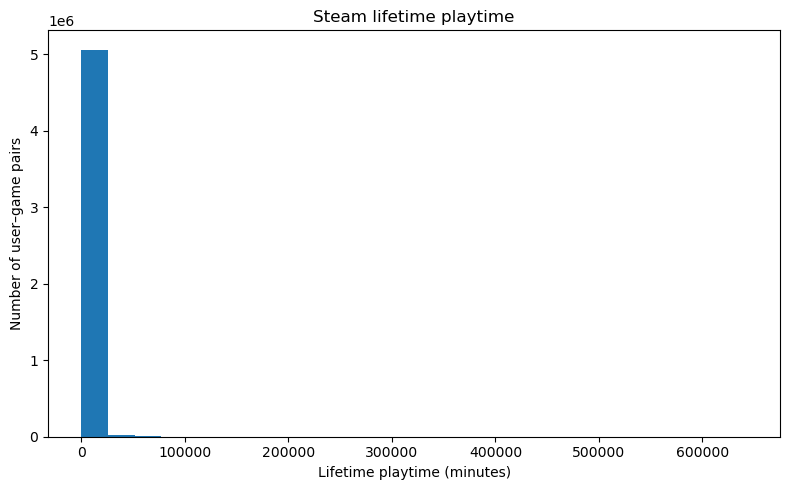

In [161]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(merged_deduped["playtime_forever"].dropna(), bins=25)

ax.set_title("Steam lifetime playtime")
ax.set_xlabel("Lifetime playtime (minutes)")
ax.set_ylabel("Number of user–game pairs")

plt.tight_layout()
plt.show()

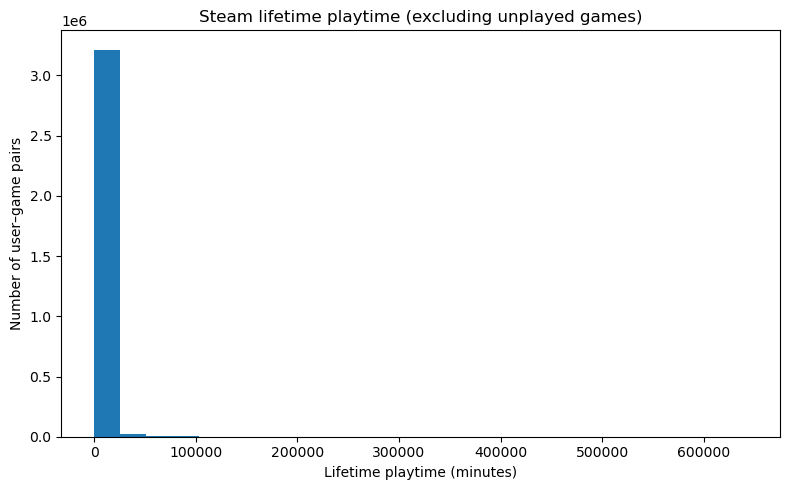

In [162]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(non_zero_playtimes["playtime_forever"].dropna(), bins=25)

ax.set_title("Steam lifetime playtime (excluding unplayed games)")
ax.set_xlabel("Lifetime playtime (minutes)")
ax.set_ylabel("Number of user–game pairs")

plt.tight_layout()
plt.show()

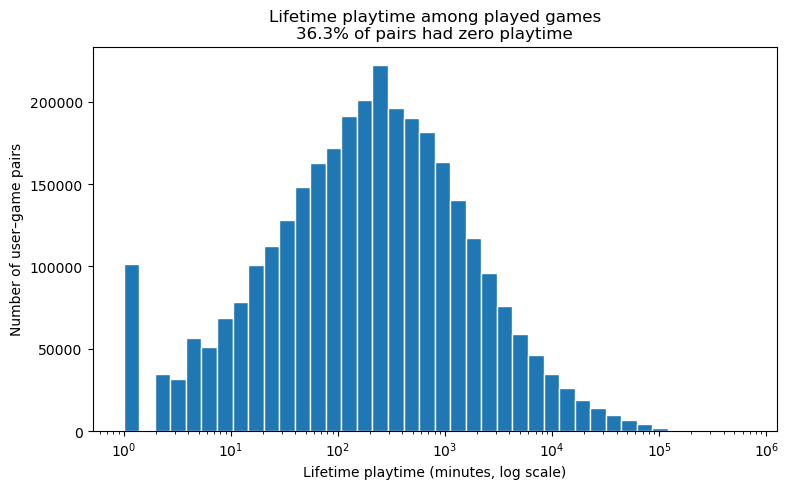

In [163]:
playtime = merged_deduped["playtime_forever"].dropna()
positive = playtime[playtime > 0]
zero_share = (playtime == 0).mean()

bins = np.geomspace(positive.min(), positive.max(), num=41)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(positive, bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Lifetime playtime (minutes, log scale)")
ax.set_ylabel("Number of user–game pairs")
ax.set_title(
    f"Lifetime playtime among played games\n{zero_share:.1%} of pairs had zero playtime"
)

plt.tight_layout()
plt.show()

### Is there a correlation between the number of hours played in a game, and whether a recommendation is positive or not?

                  mean  count
playtime_bin                 
0-1           0.638871   3046
1-5            0.82867   6111
5-10          0.889389   4665
10-25         0.917294   7835
25-50         0.922064   5697
50-100        0.928297   4951
100-400       0.931064   7108
400+          0.933419   4686


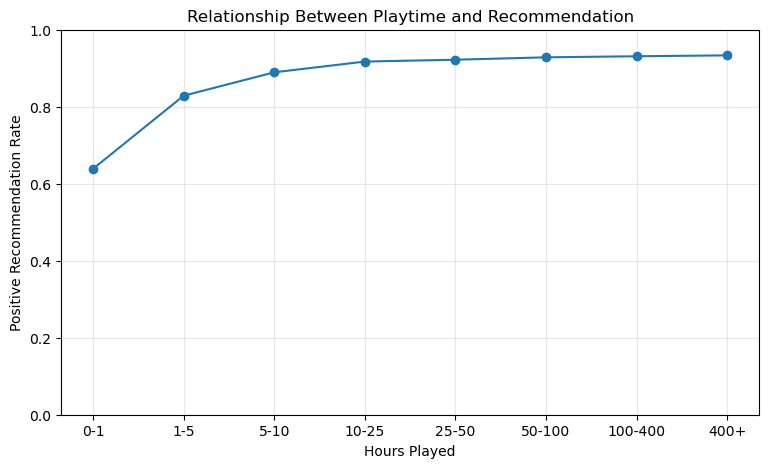

In [164]:
reviewed = has_recommendation.dropna(subset=["recommend"]).copy()

reviewed["hours"] = reviewed["playtime_forever"] / 60

bins = [0, 1, 5, 10, 25, 50, 100, 400, float("inf")]
labels = ["0-1", "1-5", "5-10", "10-25", "25-50", "50-100", "100-400", "400+"]

reviewed["playtime_bin"] = pd.cut(
    reviewed["hours"], bins=bins, labels=labels, include_lowest=True
)

results = reviewed.groupby("playtime_bin", observed=True)["recommend"].agg(
    ["mean", "count"]
)

print(results)

plt.figure(figsize=(9, 5))

plt.plot(results.index.astype(str), results["mean"], marker="o")

plt.xlabel("Hours Played")
plt.ylabel("Positive Recommendation Rate")
plt.title("Relationship Between Playtime and Recommendation")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

### Does median game time have an association with positive recommendation rate?

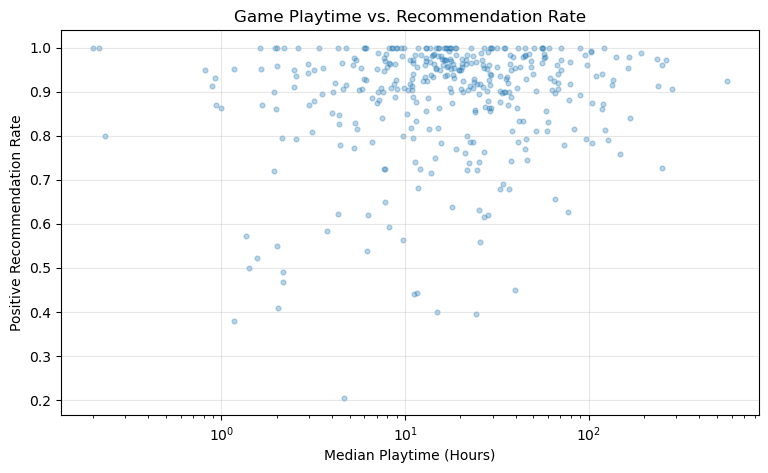

In [165]:
# Aggregate by game
game_stats = (
    reviewed.groupby("item_id")
    .agg(
        median_playtime=("playtime_forever", "median"),
        recommend_rate=("recommend", "mean"),
        review_count=("recommend", "count"),
    )
    .reset_index()
)

# Require at least 20 reviews per game
game_stats = game_stats[game_stats["review_count"] >= 20]


# Convert minutes to hours
game_stats["median_hours"] = game_stats["median_playtime"] / 60

plt.figure(figsize=(9, 5))

plt.scatter(game_stats["median_hours"], game_stats["recommend_rate"], alpha=0.3, s=12)

plt.xscale("log")
plt.xlabel("Median Playtime (Hours)")
plt.ylabel("Positive Recommendation Rate")
plt.title("Game Playtime vs. Recommendation Rate")
plt.grid(alpha=0.3)
plt.show()

In [166]:
rho, p_value = spearmanr(game_stats["median_hours"], game_stats["recommend_rate"])

print(f"Rho value: {rho}")
print(f"P-value: {p_value}")

Rho value: 0.061243295661417695
P-value: 0.2405730344121512


From the given $\rho = 0.0612$, we would conclude that there is practically no real monotonic association between `median_playtime (hours)` and `Positive Recommendation Rate`.
Since p-val > 0.05, we fail to reject the null hypothesis.

25th percentile: 8.14 hours
75th percentile: 36.72 hours
             avg_recommend_rate  num_games  num_reviews
length_group                                           
Short                  0.848325         93         4343
Medium                 0.899837        184        12954
Long                   0.900829         92        17483


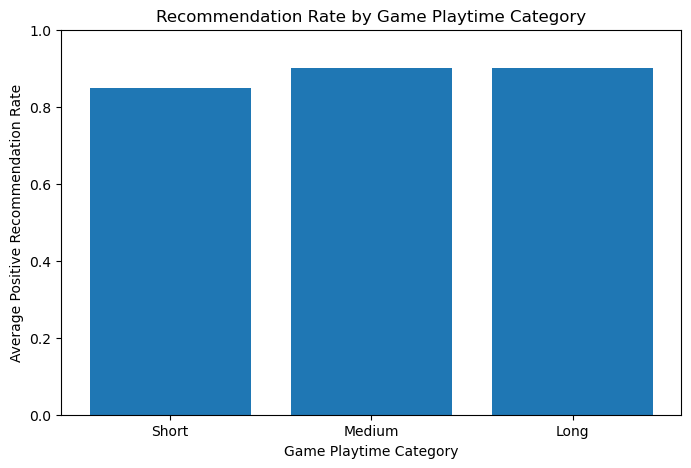

In [167]:
q25 = game_stats["median_hours"].quantile(0.25)
q75 = game_stats["median_hours"].quantile(0.75)

print(f"25th percentile: {q25:.2f} hours")
print(f"75th percentile: {q75:.2f} hours")

game_stats["length_group"] = pd.cut(
    game_stats["median_hours"],
    bins=[-np.inf, q25, q75, np.inf],
    labels=["Short", "Medium", "Long"]
)

group_stats = (
    game_stats.groupby("length_group", observed=True)
    .agg(
        avg_recommend_rate=("recommend_rate", "mean"),
        num_games=("item_id", "count"),
        num_reviews=("review_count", "sum")
    )
)

print(group_stats)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    group_stats.index.astype(str),
    group_stats["avg_recommend_rate"]
)

plt.xlabel("Game Playtime Category")
plt.ylabel("Average Positive Recommendation Rate")
plt.title("Recommendation Rate by Game Playtime Category")
plt.ylim(0, 1)

plt.show()